- **A title that says what we see**, not just what it is.
- **Names on both axes**, and the unit when there is one.
- **One colour, unless the colour means something**, and never colour only for decoration.
- **Bars start at zero**, and are sorted.
- **Say what you left out**: the missing values, the cut-off axis, the outliers. And **say how many** listings are behind the picture.
- **Do not draw what you cannot read**: too many categories, too many colours, 3D effects.

> **Notes: the words to remember**
>
> - **figure**: the whole picture, like a sheet of paper.
> - **axes** (`ax`): one chart on the figure, with its own x-axis and y-axis.
> - `fig, ax = plt.subplots()`: makes a new figure with one axes on it. We draw *on* the axes.
> - **histogram**: divides the values into intervals and counts how many fall in each one.
> - **bins**: the intervals of a histogram. More bins give a more detailed picture.
> - `dropna()`: removes the missing values. A chart can only draw what exists.
> - `plt.show()`: shows the picture.

In [83]:
def pp(msg=None, value=None):
    if msg is not None:
        print(msg)
    if value is not None:
        print(value)
    print('=' * 100)

1 Set up, and the first histogram
Import the libraries, choose the theme whitegrid, and load the table with parse_dates.
Draw a histogram of number_of_reviews with pure matplotlib (ax.hist, 50 bins). What do
you see? Then draw the same with seaborn (sns.histplot), with a title that says what we
see and names on both axes. How is it different?

(4574, 73)


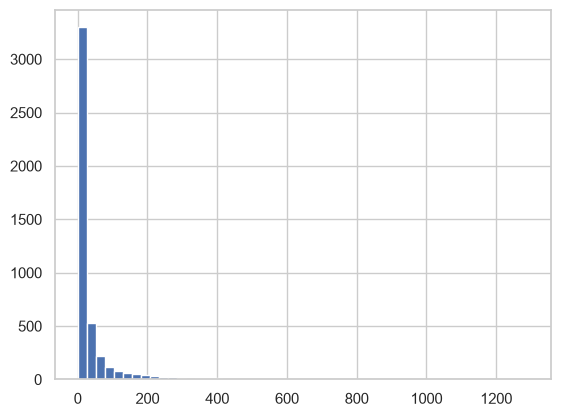

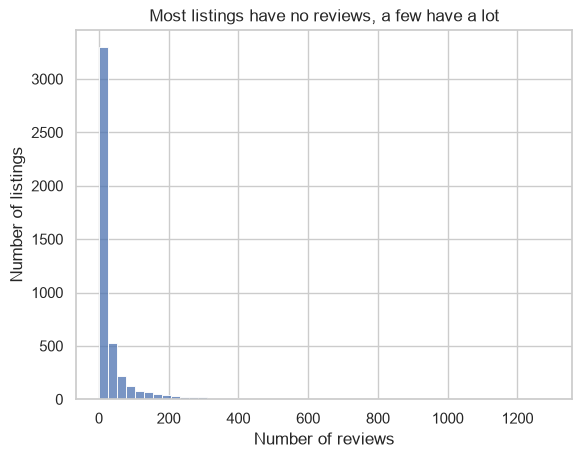

In [84]:
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns

sns.set_theme(style='whitegrid')

date_columns = ['last_scraped', 'calendar_last_scraped', 'first_review', 'last_review']
listings = pd.read_csv('listings_clean.csv', parse_dates=date_columns)
pp(listings.shape)

fig, ax = plt.subplots()
ax.hist(listings['number_of_reviews'].dropna(), bins=50)
plt.show()
fig.savefig('1.png', dpi=150, bbox_inches='tight')

fig, ax = plt.subplots()
sns.histplot(data=listings, x='number_of_reviews', bins=50, ax=ax)
ax.set_title('Most listings have no reviews, a few have a lot')
ax.set_xlabel('Number of reviews')
ax.set_ylabel('Number of listings')
plt.show()
fig.savefig('2.png', dpi=150, bbox_inches='tight')

2 Mean, median and the fence
Calculate the median, the mean and the upper fence of number_of_reviews with the IQR
rule (the same as in lab 6). Draw the histogram again, with a vertical line for each of
them, a label on each line and a legend. Which line is furthest to the right, and why?

Answer:
Upper fence, because it limits the range (lower/upper).

Median:
9.0
Mean:
35.75404459991255
Upper fence:
69.5


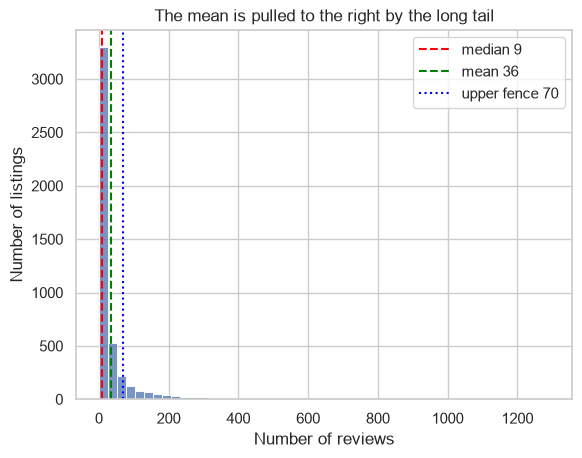

In [85]:
median = listings['number_of_reviews'].median()
mean = listings['number_of_reviews'].mean()
q1 = listings['number_of_reviews'].quantile(0.25)
q3 = listings['number_of_reviews'].quantile(0.75)
iqr = q3 - q1
upper = q3 + 1.5 * iqr
lower = q1 - 1.5 * iqr

pp("Median:", median)
pp("Mean:", mean)
pp("Upper fence:", upper)
# pp("Lower fence:", lower)

fig, ax = plt.subplots()
sns.histplot(data=listings, x='number_of_reviews', bins=50, ax=ax)

ax.axvline(median, color='red', linestyle='--', label=f'median {median:,.0f}')
ax.axvline(mean, color='green', linestyle='--', label=f'mean {mean:,.0f}')
ax.axvline(upper, color='blue', linestyle=':', label=f'upper fence {upper:,.0f}')
# ax.axvline(upper, color='gray', linestyle=':', label=f'lower fence {lower:,.0f}')

ax.set_title('The mean is pulled to the right by the long tail')
ax.set_xlabel('Number of reviews')
ax.set_ylabel('Number of listings')
ax.legend()

plt.show()
fig.savefig('3.png', dpi=150, bbox_inches='tight')

3 With and without the outliers
Mark the outliers in a column reviews_outlier. Draw two charts side by side with
plt.subplots(1, 2): all listings on the left, and without the outliers on the right. Put the
number of outliers in the title of the right chart. What does the right chart show that the
left one does not?

Answer:
The right chart shows tail values.

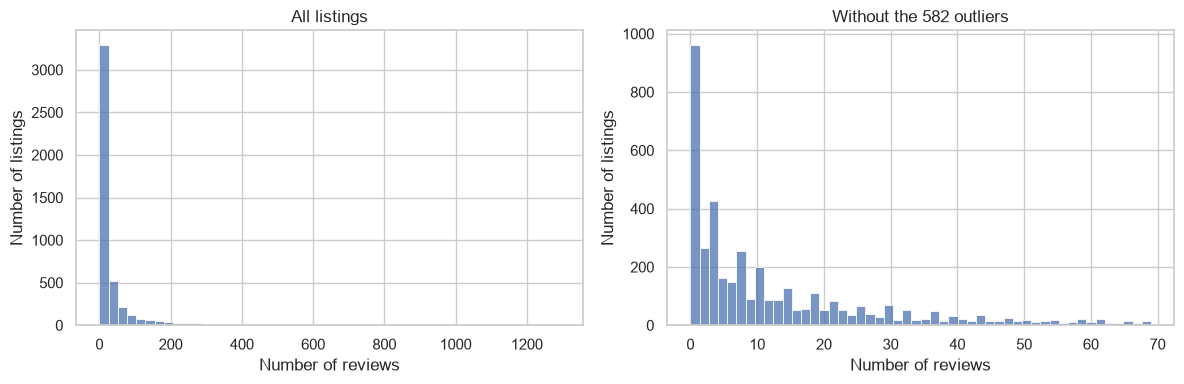

In [86]:
listings['reviews_outlier'] = listings['number_of_reviews'] > upper

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=listings, x='number_of_reviews', bins=50, ax=axes[0])
sns.histplot(data=listings[~listings['reviews_outlier']], x='number_of_reviews', bins=50, ax=axes[1])

axes[0].set_title('All listings')
axes[1].set_title('Without the 582 outliers')

for ax in axes:
    ax.set_xlabel('Number of reviews')
    ax.set_ylabel('Number of listings')

plt.tight_layout()
plt.show()
fig.savefig('4.png', dpi=150, bbox_inches='tight')

4 The boxplot
Draw a boxplot of number_of_reviews for the two big room types (Entire home/apt and
Private room; use isin). Most of the picture is empty, so show only 0 to 300 with set_ylim.
Say in the title how many listings with more than 300 reviews are outside the picture
(count them first). Which room type has the higher median? Note: a boxplot can show a
red MatplotlibDeprecationWarning about vert. It is a warning, not an error, and your chart
is fine.

Answer:
Private rooms have higher median.

C:\Users\User\AppData\Local\Temp\ipykernel_1180\1347440566.py:5: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  more_than_300 = two_types[listings['number_of_reviews'] > 300]


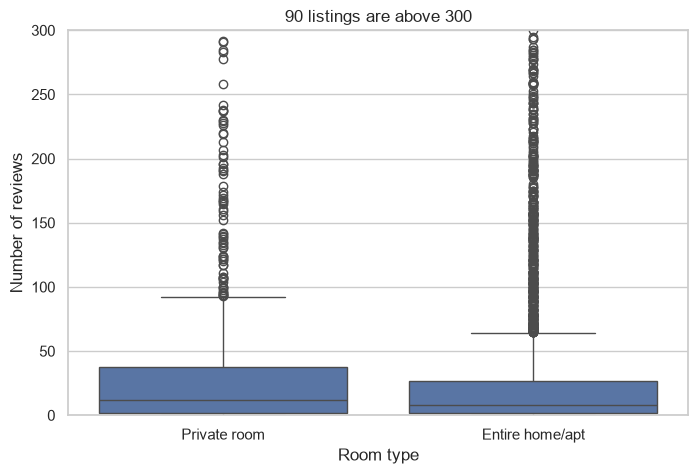

In [87]:
two_types = listings[listings['room_type'].isin(['Entire home/apt', 'Private room'])]
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=two_types, x= 'room_type', y='number_of_reviews', ax=ax)

more_than_300 = two_types[listings['number_of_reviews'] > 300]

ax.set_ylim(0,300)
# ax.set_ylim(0,50)
ax.set_title(f'{len(more_than_300)} listings are above 300')
ax.set_xlabel('Room type')
ax.set_ylabel('Number of reviews')

plt.show()
fig.savefig('5.png', dpi=150, bbox_inches='tight')

In [88]:
check_plot = (listings[listings['room_type'].isin(['Private room', 'Entire home/apt'])]
    .groupby('room_type')['number_of_reviews']
    .describe()
)
pp(check_plot)

                  count       mean        std  min  25%   50%   75%     max
room_type                                                                  
Entire home/apt  3760.0  34.231649  76.464806  0.0  2.0   8.0  27.0  1293.0
Private room      787.0  40.537484  84.363382  0.0  2.0  12.0  38.0   867.0


5 The bar charts
(a) Draw a countplot of the number of listings per room_type, the biggest first. (b)
Calculate the median number_of_reviews and the number of listings for every
neighbourhood_cleansed, highest median first. Make a label with the neighbourhood and
the count in brackets, and draw the median as horizontal bars with barplot. Which
neighbourhood has the highest median, and which has the most listings?

Answer:
highest median - Södermalms
most listings - Södermalms

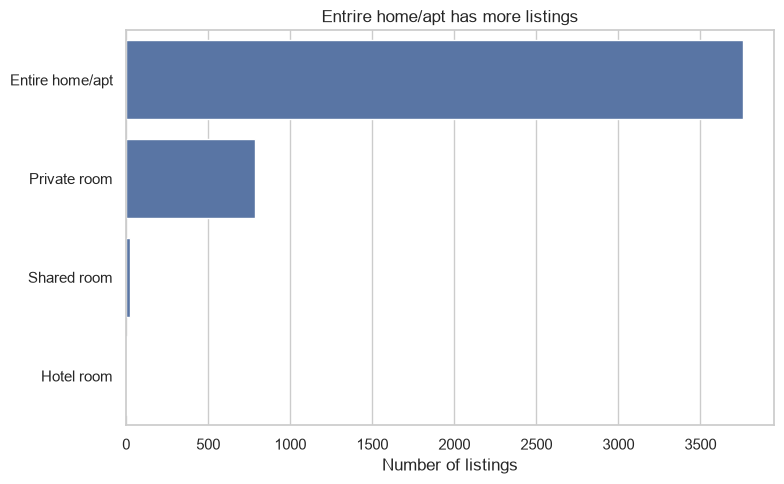

  neighbourhood_cleansed  median_reviews  number_of_listings  \
0             Södermalms            17.0                1145   
1           Kungsholmens            12.0                 420   
2              Norrmalms            10.0                 469   

                label  
0   Södermalms (1145)  
1  Kungsholmens (420)  
2     Norrmalms (469)  


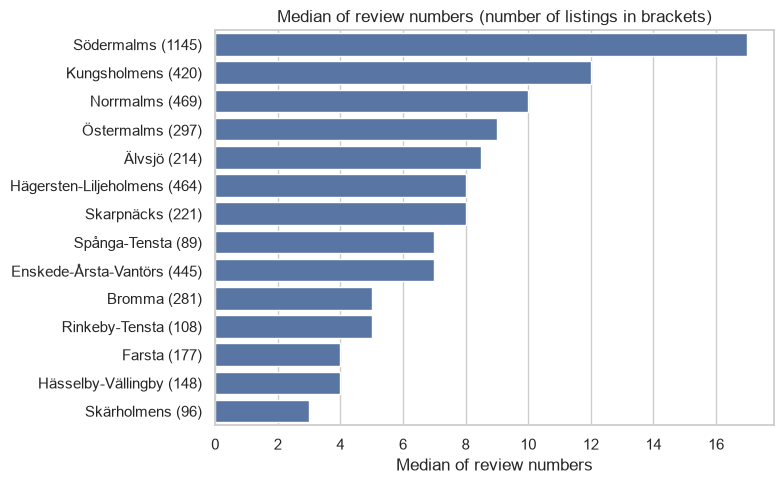

In [89]:
# (a)
order = listings['room_type'].value_counts().index

fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(data=listings, y='room_type', order=order, ax=ax)
ax.set_title('Entrire home/apt has more listings')
ax.set_xlabel('Number of listings')
ax.set_ylabel('')
plt.tight_layout()
plt.show()
fig.savefig('6.png', dpi=150, bbox_inches='tight')

# (b)
by_neighbourhood = (
    listings.groupby('neighbourhood_cleansed')
    .agg(
        median_reviews=('number_of_reviews', 'median'),
        number_of_listings=('id', 'count')
    )
    .sort_values('median_reviews', ascending=False)
    .reset_index()
)

by_neighbourhood['label'] = (by_neighbourhood['neighbourhood_cleansed'] + 
    ' (' + by_neighbourhood['number_of_listings'].astype(str) + ')')

pp(by_neighbourhood.head(3))

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=by_neighbourhood, x='median_reviews', y='label', ax=ax)
ax.set_title('Median of review numbers (number of listings in brackets)')
ax.set_xlabel('Median of review numbers')
ax.set_ylabel('')
plt.tight_layout()
plt.show()
fig.savefig('7.png', dpi=150, bbox_inches='tight')


6 The scatter plot
Draw availability_365 (x) against number_of_reviews (y) as a scatter plot with alpha=0.3,
and with the y-axis from 0 to 300. Then colour the dots by room_type, for the two big types,
with hue. Do you see a pattern? How does it match the correlation of 0.18 from lab 6?

Answer:
As the correlation is positive, higher availability leads to higher number of reviews,
which can be seen on the scatter plots.

91 listings are above the top of the picture


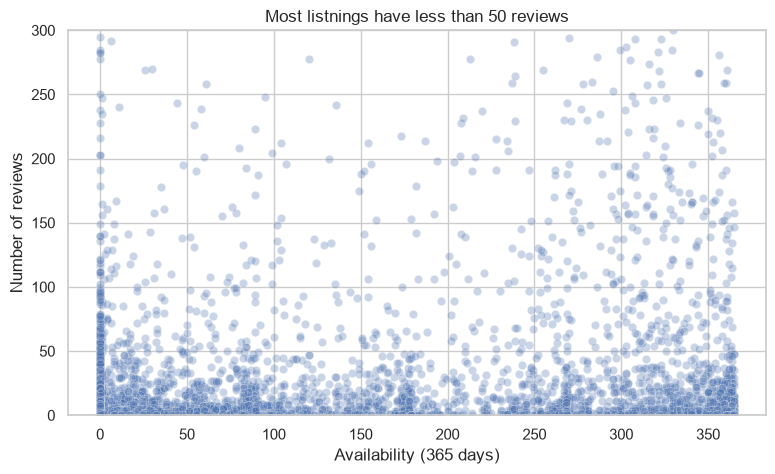

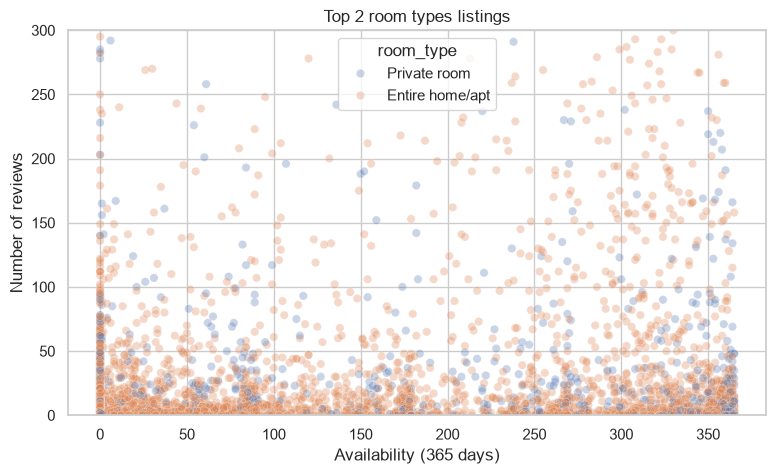

In [90]:
print((listings['number_of_reviews'] > 300).sum(), 'listings are above the top of the picture')

fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=listings, x='availability_365', y='number_of_reviews', ax=ax, alpha=0.3)
ax.set_ylim(0, 300)
ax.set_title('Most listnings have less than 50 reviews')
ax.set_xlabel('Availability (365 days)')
ax.set_ylabel('Number of reviews')
plt.show()
fig.savefig('8.png', dpi=150, bbox_inches='tight')

top_room_types = listings['room_type'].value_counts().index[:2]
listings_top_room_types = listings[listings['room_type'].isin(top_room_types)]
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=listings_top_room_types, 
    x='availability_365', y='number_of_reviews', ax=ax, alpha=0.3, hue='room_type')
ax.set_ylim(0, 300)
ax.set_title('Top 2 room types listings')
ax.set_xlabel('Availability (365 days)')
ax.set_ylabel('Number of reviews')
plt.show()
fig.savefig('9.png', dpi=150, bbox_inches='tight')

7 The heatmap and the line chart
(a) Draw a heatmap of the correlations between number_of_reviews, price, accommodates,
bedrooms, availability_365, review_scores_rating, minimum_nights and days_since_review,
with the numbers in the squares and the scale from -1 to 1. (b) Count the listings per year
of the last review (last_review.dt.year) and draw a line chart. What is special about the
last year, and what does it mean?

Answer:
There is a spike from 2025 to 2026 year, which means that most of the listnings are 1 year fresh.

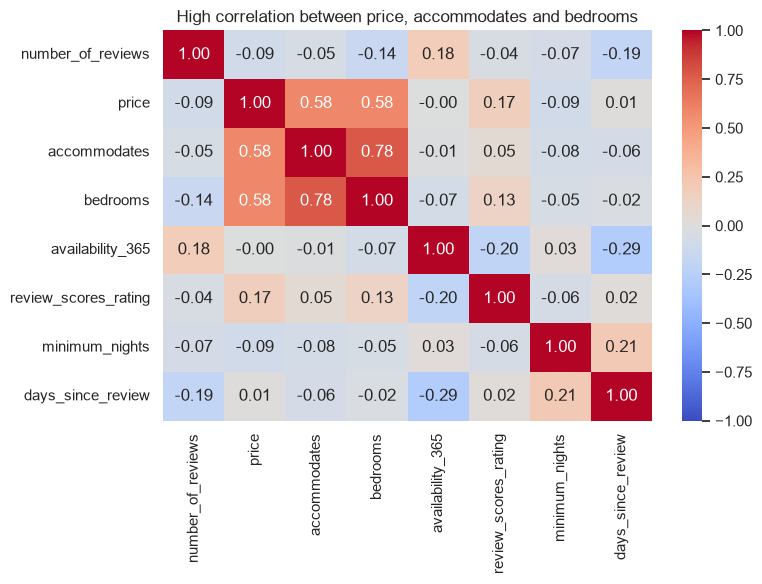

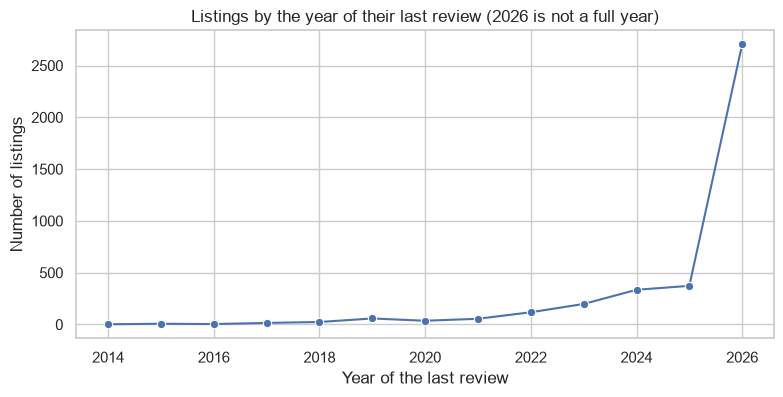

In [91]:
# (a)
columns = [
    'number_of_reviews', 
    'price', 
    'accommodates', 
    'bedrooms', 
    'availability_365', 
    'review_scores_rating',
    'minimum_nights',
    'days_since_review'
]
corr = listings[columns].corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
ax.set_title('High correlation between price, accommodates and bedrooms')
plt.tight_layout()
plt.show()
fig.savefig('10.png', dpi=150, bbox_inches='tight')

# (b)
per_year = listings['last_review'].dt.year.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9,4))
sns.lineplot(x=per_year.index, y=per_year.values, marker='o', ax= ax)
ax.set_title('Listings by the year of their last review (2026 is not a full year)')
ax.set_xlabel('Year of the last review')
ax.set_ylabel('Number of listings')
plt.show()
fig.savefig('11.png', dpi=150, bbox_inches='tight')

8 A chart that lies, and a chart that does not
Calculate the median review_scores_rating for the two big room types. Draw the same
two bars twice, side by side: once with the y-axis from 0 and once with the y-axis from
4.88 to 4.93. Give each chart a title. What does the second chart make you believe? Then
save the honest chart as rating_per_room_type.png with fig.savefig, and check that the
file is in your folder.

Answer:
At first glans "Entire home/apt"s have much more higher rating median than "Private room"s.

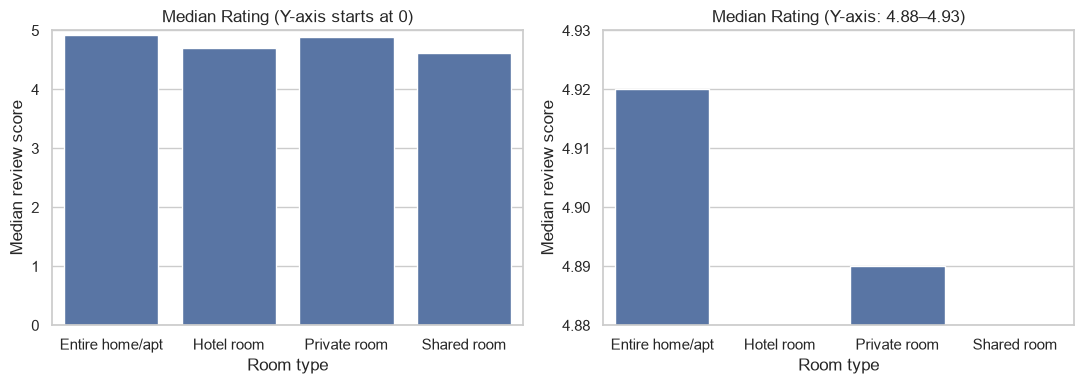

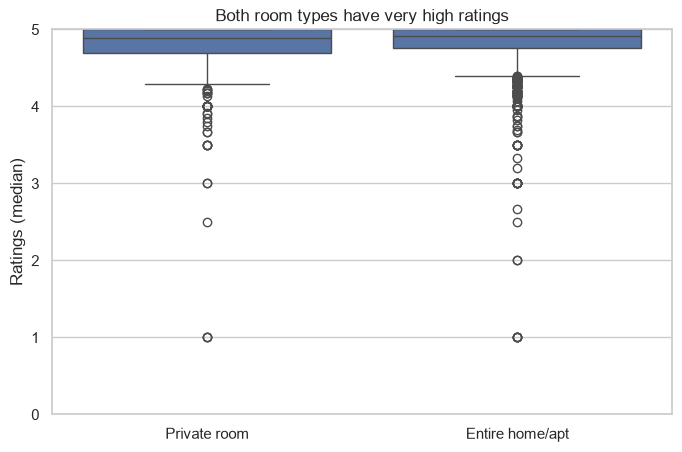

In [92]:
# by_type_medians = listings.groupby('room_type').agg(
#     median_rating=('review_scores_rating', 'median'),
#     number_of_listings=('id', 'count')
# ).sort_values('number_of_listings', ascending=False)

by_type_medians = listings.groupby('room_type')['review_scores_rating'].median()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(x=by_type_medians.index, y=by_type_medians.values, ax=axes[0])
axes[0].set_title('Median Rating (Y-axis starts at 0)')
axes[0].set_ylim(0, 5.00)
axes[0].set_xlabel('Room type')
axes[0].set_ylabel('Median review score')
sns.barplot(x=by_type_medians.index, y=by_type_medians.values, ax=axes[1])
axes[1].set_title('Median Rating (Y-axis: 4.88–4.93)')
axes[1].set_ylim(4.88, 4.93)
axes[1].set_xlabel('Room type')
axes[1].set_ylabel('Median review score')
plt.tight_layout()
plt.show()
fig.savefig('12.png', dpi=150, bbox_inches='tight')

top_types = listings[listings['room_type'].isin(['Entire home/apt', 'Private room'])]
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=top_types, x='room_type', y='review_scores_rating', ax=ax)
ax.set_ylim(0, 5.00)
ax.set_title('Both room types have very high ratings')
ax.set_xlabel('')
ax.set_ylabel('Ratings (median)')
fig.savefig('reviews_per_room_type.png', dpi=150, bbox_inches='tight')
plt.show()